In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [5]:
train_path = r"D:\FinTech\MasterClass-FinTech-01\session_3\titanic\train.csv"
test_path = r"D:\FinTech\MasterClass-FinTech-01\session_3\titanic\test.csv"
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
display(train_df.head())
test_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [9]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## 3 · Preprocess the data

`Sex` is encoded as `male = 1`, `female = 0`, and `Embarked` gets a fixed mapping `S = 0`, `C = 1`, `Q = 2` (missing values are filled with `S`, the most common port). Code the categories with an explicit mapping rather than `cat.codes`, so the same value always maps to the same number in the training and test subsets.

`Age` still has missing values. To avoid leakage, it is **not** filled yet: the median is learned from the training rows only, after the split, and the same value is then used for the validation rows.

In [10]:
train_df["Sex"] = train_df["Sex"].map({"male": 1, "female": 0})

In [11]:
train_df["Embarked"] = train_df["Embarked"].fillna("S").map({"S": 0, "C": 1, "Q": 2})

## B · Age imputation and model training

The median age is computed on `X_train` only and stored in `median_age`; the same value then fills missing ages in both `X_train` and `X_val`. The validation rows never influence the imputation statistic, so the evaluation stays honest. The cell below verifies the value and that no missing ages remain.

In [14]:
data = train_df
X = data[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]
y = data['Survived']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Learn the imputation statistic from TRAINING rows only, then reuse it for both subsets. it 
median_age = X_train['Age'].median()

X_train = X_train.copy()
X_val = X_val.copy()
X_train['Age'] = X_train['Age'].fillna(median_age)
X_val['Age'] = X_val['Age'].fillna(median_age)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [13]:
print(f"Median age learned from training rows: {median_age}")
print(f"Missing ages in training rows:   {X_train['Age'].isna().sum()}")
print(f"Missing ages in validation rows: {X_val['Age'].isna().sum()}")

Median age learned from training rows: 28.0
Missing ages in training rows:   0
Missing ages in validation rows: 0


In [17]:
y_pred = rf.predict(X_val)


## A · Feature importances 

Features sorted by importance:
Sex         0.272301
Fare        0.266766
Age         0.253908
Pclass      0.085709
SibSp       0.048704
Parch       0.038946
Embarked    0.033668


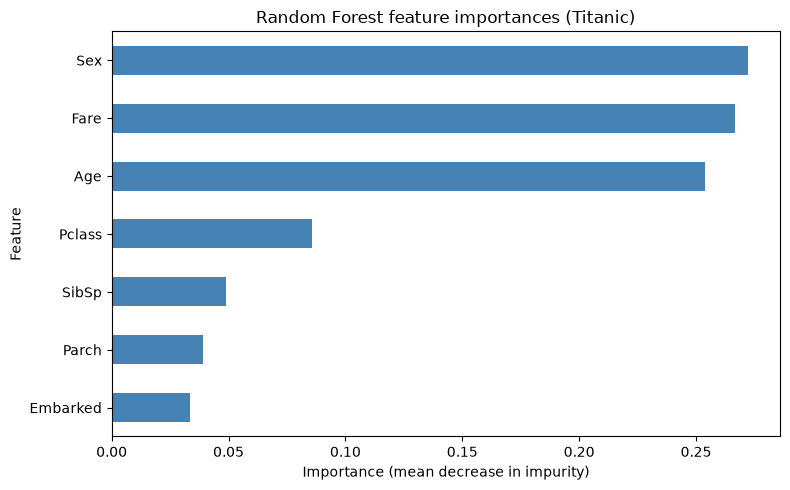

In [18]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print("Features sorted by importance:")
print(importances.to_string())

fig, ax = plt.subplots(figsize=(8, 5))
importances.sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Random Forest feature importances (Titanic)')
ax.set_xlabel('Importance (mean decrease in impurity)')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

## C · Classification report and confusion matrix


In [19]:
print(classification_report(y_val, y_pred, target_names=['Did not survive', 'Survived']))

                 precision    recall  f1-score   support

Did not survive       0.83      0.87      0.85       105
       Survived       0.80      0.76      0.78        74

       accuracy                           0.82       179
      macro avg       0.82      0.81      0.81       179
   weighted avg       0.82      0.82      0.82       179



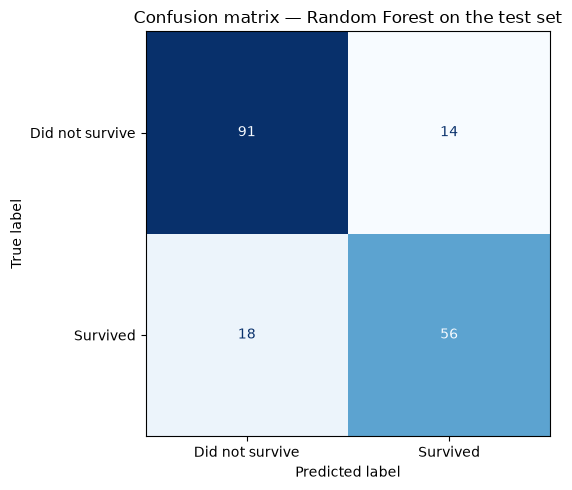

In [20]:
cm = confusion_matrix(y_val, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Did not survive', 'Survived'])
disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)
ax.set_title('Confusion matrix — Random Forest on the test set')
plt.tight_layout()
plt.show()

## D · Error analysis

<!-- Add your explanation of false positives, false negatives, and which class has the higher recall here. -->

In this context, an FP (False Positive) means that an individual did not survive, but the model predicts that they "survived."
An FN (False Negative) means that an individual survived, but the model predicts that they "did not survive."
based on classification report, the recall for "did not survive" class is more than other class. The recall for the "Did not survive" class is 87%, while the recall for the "Survived" class is 76%. This means the model performs better at identifying individuals who did not survive, and it misses approximately 24% of the actual survivors.

In [21]:
tn, fp, fn, tp = cm.ravel()
print(f"True negatives  (did not survive, predicted did not survive): {tn}")
print(f"False positives (did not survive, predicted survived):        {fp}")
print(f"False negatives (survived, predicted did not survive):        {fn}")
print(f"True positives  (survived, predicted survived):               {tp}")

True negatives  (did not survive, predicted did not survive): 91
False positives (did not survive, predicted survived):        14
False negatives (survived, predicted did not survive):        18
True positives  (survived, predicted survived):               56


## E · How does tree depth change the rules and training performance?

In [22]:
rows = []
for depth in [1, 2, 4, 8]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)
    rows.append({
        'max_depth (requested)': depth,
        'actual tree depth': tree.get_depth(),
        'number of leaves': tree.get_n_leaves(),
        'training accuracy': accuracy_score(y_train, tree.predict(X_train)),
    })

depth_table = pd.DataFrame(rows)
depth_table

,max_depth (requested),actual tree depth,number of leaves,training accuracy
0,1,1,2,0.787921
1,2,2,4,0.803371
2,4,4,15,0.839888
3,8,8,58,0.898876


As shown in the results table, the model's accuracy increases as the tree depth grows. This is because the number of leaf nodes increases, enabling the tree to learn more patterns and, consequently, make better predictions. However, an increase in accuracy on the training data alone does not necessarily indicate a better model, as overfitting may have occurred. To investigate this, we evaluate the model on the validation (val) set and compare the corresponding performance plots.

In [23]:
rows = []

for depth in [1, 2, 4, 8]:
    dtree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    dtree.fit(X_train, y_train)

    rows.append({
        'max_depth': depth,
        'training accuracy': accuracy_score(
            y_train, dtree.predict(X_train)
        ),
        'test accuracy': accuracy_score(
            y_val, dtree.predict(X_val)
        ),
        'actual depth': dtree.get_depth(),
        'number of leaves': dtree.get_n_leaves()
    })

depth_comparison = pd.DataFrame(rows)
display(depth_comparison)

,max_depth,training accuracy,test accuracy,actual depth,number of leaves
0,1,0.787921,0.782123,1,2
1,2,0.803371,0.765363,2,4
2,4,0.839888,0.798883,4,15
3,8,0.898876,0.793296,8,58


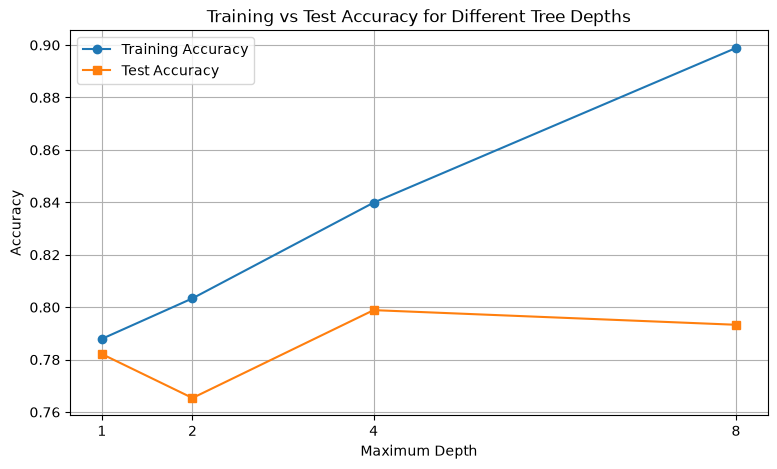

In [24]:
plt.figure(figsize=(9, 5))

plt.plot(
    depth_comparison['max_depth'],
    depth_comparison['training accuracy'],
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    depth_comparison['max_depth'],
    depth_comparison['test accuracy'],
    marker='s',
    label='Test Accuracy'
)

plt.xlabel('Maximum Depth')
plt.ylabel('Accuracy')
plt.title('Training vs Test Accuracy for Different Tree Depths')
plt.xticks([1, 2, 4, 8])
plt.legend()
plt.grid(True)
plt.show()

As indicated in the plot, the validation accuracy appears to decline for depths greater than 4. While this drop is not substantial, we could increase the depth further to conduct a more thorough analysis and confirm whether overfitting is taking place. In general, employing a Random Forest and increasing the amount of data are effective strategies for mitigating or eliminating overfitting in this context.

## F · Kaggle submission 🚢

The Kaggle test set (`titanic/test.csv`) has no survival labels, so it cannot be scored locally. Following the assignment hint, the final model is refit on **all** 891 training passengers and then used to predict the 418 test passengers. The CSV is written in the same format as `gender_submission.csv` (`PassengerId`, `Survived`).

In [25]:
# Final model: refit on ALL training rows (assignment hint)
median_age_full = train_df['Age'].median()
median_fare_full = train_df['Fare'].median()
X_full = train_df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
X_full['Age'] = X_full['Age'].fillna(median_age_full)
X_test = test_df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']].copy()
X_test['Sex'] = X_test['Sex'].map({'male': 1, 'female': 0})
X_test['Embarked'] = X_test['Embarked'].fillna('S').map({'S': 0, 'C': 1, 'Q': 2})
X_test['Age'] = X_test['Age'].fillna(median_age_full)
X_test['Fare'] = X_test['Fare'].fillna(median_fare_full)

final_rf = RandomForestClassifier(n_estimators=100, random_state=42)
final_rf.fit(X_full, train_df['Survived'])
test_predictions = final_rf.predict(X_test)
submission = pd.DataFrame({
    'PassengerId': test_df['PassengerId'],
    'Survived': test_predictions,
})
submission.to_csv('titanic/submission.csv', index=False)
print(f"Saved {len(submission)} predictions to titanic/submission.csv")
print(f"Predicted survival rate: {submission['Survived'].mean():.3f}")
submission.head(10)

Saved 418 predictions to titanic/submission.csv
Predicted survival rate: 0.364


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,1
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0


the accuracy score in kaggle : 0.7559